In [1]:
import logging
logging.basicConfig(level=logging.INFO, force=True)


from networkx.drawing import (
    draw as nx_draw,
    spring_layout,
    kamada_kawai_layout ,
)

from mupt.trees.subselect import NodePredicate
from mupt.mupr.primitives import (
    Primitive,
    RootPrimitive,
    CompositePrimitive,
)
from mupt.mupr.properties import is_atom, is_superatomic, is_subdominant

from mupt.interfaces.smiles import primitive_from_smiles
from mupt.interfaces.mosdef.mbuild import primitive_to_mbuild

INFO:rdkit:Enabling RDKit 2026.09.1 jupyter extensions
INFO:freud.msd:Using SciPy's fftpack for FFTs


# Linear PAAm homopolymer

In [2]:
num_mols : int = 3
DOP : int = 10

## Assemble MuPT repr

In [3]:
lexicon = {
    'head' : primitive_from_smiles('[H:1]-[C:2]CC(=O)[N:1](-[H])-[*:2]', label="_A"),
    'mid'  : primitive_from_smiles('[*:1]-[C:2]CC(=O)[N:1](-[H])-[*:2]', label="_B"),
    'tail' : primitive_from_smiles('[*:1]-[C:2]CC(=O)[N:1](-[H])-[H:2]', label="_C"),
}

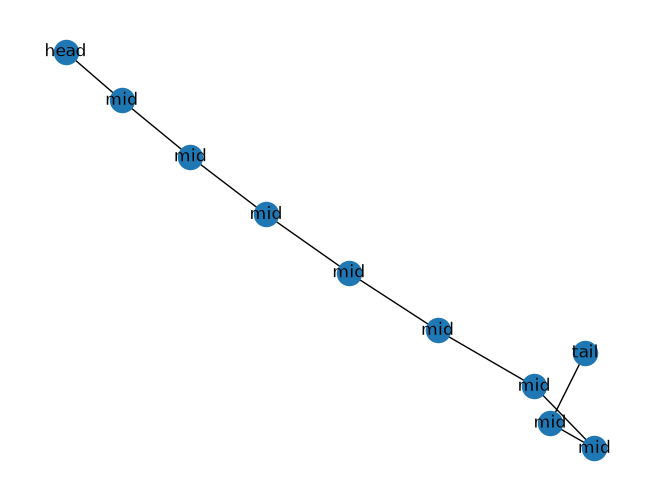

In [4]:
from networkx import get_node_attributes, connected_components
from mupt.graphs.generators import path_graph_from_sequence


label_attr : str = 'label'
sequence_graph = path_graph_from_sequence(
    ['head'] + (DOP - 2)*['mid'] + ['tail'],
    label_attr=label_attr,
)

nx_draw(
    sequence_graph,
    with_labels=True,
    labels=get_node_attributes(sequence_graph, label_attr),
)

### Select, connect, then inspect

In [5]:
# predicate : NodePredicate[Primitive] = lambda prim : is_atom(prim) and prim.element.symbol != 'H'
# predicate : NodePredicate[Primitive] = lambda prim: isinstance(prim.parent, CompositePrimitive)
# predicate : NodePredicate[Primitive] = is_superatomic
predicate : NodePredicate[Primitive] = is_superatomic

In [6]:
molprim_prototype = CompositePrimitive()
molprim_prototype.populate_from_topology_and_lexicon(
    sequence_graph,
    lexicon,
    label_attr=label_attr,
)

system = RootPrimitive(label='system')
for i in range(num_mols):
    molprim = molprim_prototype.copy()
    molprim.label = f'molecule_{i}'
    system.attach_child(molprim)

INFO:mupt.mupr.connection.linking:Paired up 9 new edges after 1 iteration(s); 0/9 edges remain unpaired
INFO:mupt.mupr.connection.linking:Linking protocol successful! 9/9 edges were assigned Connector pairings


In [7]:
xsec = system.cross_section(predicate)
print(f'{len(list(connected_components(xsec)))} molecules')

3 molecules


<Axes: >

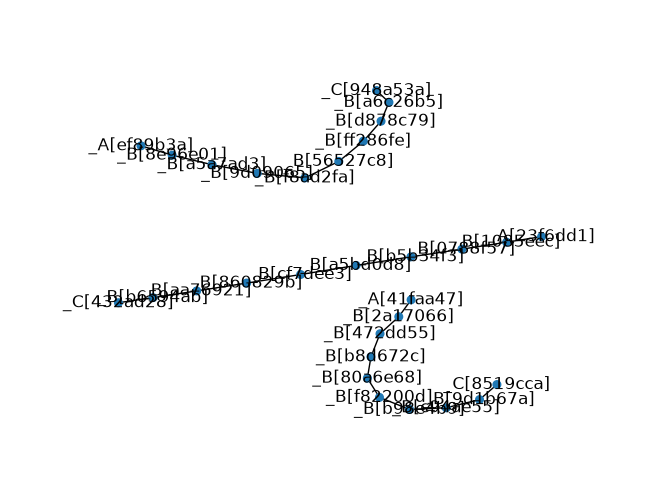

In [8]:
pos = spring_layout(xsec, dim=2)
system.visualize_cross_section(xsec, pos=pos, with_labels=True, node_size=30)

## Export to mbuild

In [9]:
compound = primitive_to_mbuild(
    system,
    predicate=predicate,
    # set False (default) to have Particles directly on Compound
    preserve_intermediates=True, 
)
... # insert downstream code here
print(compound)

<system 30 particles, 27 bonds, non-periodic, id: 5954583056>


In [10]:
# inspect direct descendants of "root" Compound which is returned
display(set(subcomp.name for subcomp in compound.children))

{'molecule_0', 'molecule_1', 'molecule_2'}

from mupt.chemistry.rdkit.depiction import set_rdkdraw_size, hide_atom_indices

set_rdkdraw_size(500, 3/2)
hide_atom_indices()

mols = compound.to_rdkit()
for atom in mols.GetAtoms():
    atom.ClearProp('atomLabel')
display(mols)

# PAMAM dendrimer

In [11]:
print(molprim.hierarchy_summary())

molecule_2
├── _A
│   ├── H-0
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
├── _B
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
├── _B
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
├── _B
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
├── _B
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
├── _B
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
├── _B
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
├── _B
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
├── _B
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
╰── _C
    ├── C-1
    ├── C-2
    ├── C-3
    ├──

In [12]:
from flowermd.library import RandomWalk
import unyt as u

from flowermd.library import Bead_Spring_DPD #check which xml your environment is pointing at
import hoomd

from flowermd.library import PhantomWalk

import warnings
import copy
warnings.filterwarnings("ignore")
from flowermd.base import Molecule

molecules = Molecule(
    num_mols=1, compound=compound, name="PAMAM", identify_connections=False
)

ref_length = 1.0 * u.Unit("nm")
ref_mass = 1.0 * u.Unit("g/mol")
ref_energy = 1.0 * u.Unit("kcal / mol")
ref_values_dict = {"length": ref_length, "mass": ref_mass, "energy": ref_energy}

system = RandomWalk(
    molecules=molecules,
    density=0.8 * u.Unit("nm**-3"),
    bond_length=1.0,
    base_units=ref_values_dict,
    seed=456,
)

system_copy = copy.deepcopy(system)

nlist = hoomd.md.nlist.Cell(buffer=0.1, exclusions=["bond"])
system.apply_forcefield(
    force_field=Bead_Spring_DPD(), kT=1.0, r_cut=1.01, nlist=nlist
)

print(system.all_molecules[0].xyz)
print(system.box)

sim = PhantomWalk(
    initial_state=system.hoomd_snapshot,
    forcefield=system.hoomd_forcefield,
    gsd_write_freq=100,
    log_write_freq=50,
    n_steps_dpd=500,
    n_steps_fire=100,
    write_at_start=True,
)

for writer in sim.operations.writers:
    if isinstance(writer, hoomd.write.GSD):
        writer.flush()

INFO:numexpr.utils:NumExpr defaulting to 11 threads.


[[-0.10150865 -0.17520634 -1.25834381]
 [ 0.8911159  -0.28419355 -1.20525615]
 [-0.02885458 -0.56717044 -1.47650953]
 [-0.24145681 -1.03420235 -0.61820802]
 [-1.19608713 -1.08948647 -0.32559116]
 [-1.09597219  1.35668631  0.09653497]
 [-1.04598487  0.40672799  0.40488616]
 [-1.11058761 -0.47837026 -0.05601248]
 [-0.50141915 -1.03281626 -0.6230252 ]
 [-0.51303226 -0.38229604 -1.38242534]
 [ 0.85302487  1.58317028 -1.39570144]
 [ 0.93075052 -0.83475818  1.59024502]
 [ 0.5292568  -0.18683286  0.94294635]
 [ 0.29058589  0.7469058   1.20972022]
 [ 0.04424741  0.99037971 -1.19934123]
 [ 0.02168062  0.69034152  1.1941633 ]
 [-0.04263573  1.5809504   0.74396419]
 [-0.40855429  0.97064123  0.04137874]
 [-0.56002216 -1.4754801   0.44779999]
 [-0.27806832 -1.19725085  1.3659996 ]
 [-0.65501272  0.99093711 -0.33106546]
 [-1.45673872  0.68878126 -0.84675652]
 [-1.16329441 -0.08930617 -0.29135541]
 [-0.16503467 -0.03194016 -0.2776941 ]
 [-1.12095011  0.00873999 -0.56850468]
 [-1.41781435  0.27647749

In [13]:
snap = sim.state.get_snapshot()
system_copy.update_system_positions(snapshot=snap)

In [14]:
snap.particles.position

array([[ 1.35164393, -0.53576913,  0.30012009],
       [-1.04617713, -0.30407739,  0.51230596],
       [-1.13181157, -1.10149362, -0.08497874],
       [-1.43889712, -0.43532018, -0.76460034],
       [-1.37386505, -1.35330034, -1.15583631],
       [ 1.41969108,  1.2564414 , -0.76887193],
       [ 1.23370207, -1.14579756, -0.49957312],
       [ 0.52538257,  1.51192164, -0.34793286],
       [-0.35896307,  1.48720082,  0.11827185],
       [ 0.28019093,  0.7298062 ,  0.25173797],
       [ 0.2359059 , -0.92922306,  0.12056415],
       [-0.05307954, -0.13726251,  0.65844983],
       [ 0.12959856, -0.16073956,  1.64132312],
       [-0.77720597, -0.56995691,  1.5401612 ],
       [-0.58213549, -1.54861118,  1.47550953],
       [-0.38752422, -1.30439354, -0.92166885],
       [ 0.53051355, -1.05768331, -1.23195401],
       [ 1.07359274, -0.22174151, -1.31151877],
       [ 0.37895485,  0.11397357, -0.67528672],
       [ 0.55764516,  0.73176245, -1.44106468],
       [-0.51993262, -0.29877284, -0.367

In [20]:
system_copy.all_molecules[0].xyz

array([[ 1.35164393, -0.53576913,  0.30012009],
       [-1.04617713, -0.30407739,  0.51230596],
       [-1.13181157, -1.10149362, -0.08497874],
       [-1.43889712, -0.43532018, -0.76460034],
       [-1.37386505, -1.35330034, -1.15583631],
       [ 1.41969108,  1.2564414 , -0.76887193],
       [ 1.23370207, -1.14579756, -0.49957312],
       [ 0.52538257,  1.51192164, -0.34793286],
       [-0.35896307,  1.48720082,  0.11827185],
       [ 0.28019093,  0.7298062 ,  0.25173797],
       [ 0.2359059 , -0.92922306,  0.12056415],
       [-0.05307954, -0.13726251,  0.65844983],
       [ 0.12959856, -0.16073956,  1.64132312],
       [-0.77720597, -0.56995691,  1.5401612 ],
       [-0.58213549, -1.54861118,  1.47550953],
       [-0.38752422, -1.30439354, -0.92166885],
       [ 0.53051355, -1.05768331, -1.23195401],
       [ 1.07359274, -0.22174151, -1.31151877],
       [ 0.37895485,  0.11397357, -0.67528672],
       [ 0.55764516,  0.73176245, -1.44106468],
       [-0.51993262, -0.29877284, -0.367

In [16]:
system_copy.gmso_system.atom_types

<TopologyPotentialView(())>

In [17]:
from gmso.parameterization import apply

In [19]:
from flowermd.base import BaseXMLForcefield
xml_path = "../flowermd/assets/forcefields/cg-lammps.xml"
lammps_ff = BaseXMLForcefield(forcefield_files=xml_path,gmso_xml=True)

KeyError: 'parameters'

In [ ]:
apply(top=system_copy.gmso_system, forcefields=lammps_ff.gmso_ff, identify_connections=False)

In [ ]:
system_copy.gmso_system.atom_types

In [ ]:
from gmso.formats.lammpsdata import write_lammpsdata
write_lammpsdata(system_copy.gmso_system, filename="PAAm.lammps", atom_style="full")